# 프롬프트 버전과 AB 비교

**이 노트북에서 할 일**

1. Ch 6 06절이 저장한 기록 파일을 읽고, 파일 내용으로 지문(SHA-256)을 계산합니다.
2. 과업 명세만 다른 세 버전을 바꾼 것·바꾼 이유와 함께 적고, 한 번씩 보내 같은 항목으로 기록합니다.
3. 세 버전 기록을 출처와 함께 JSON 파일로 저장하고, 세 버전을 한 번 더 보내 두 실행을 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다.
Ch 6 06절 노트북이 만든 기록 파일 `provider-comparison-continuity.json`을 읽습니다.

인터넷 서비스에 요청을 모두 6번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

8절은 실습 폴더의 `runs/prompt-ab-continuity.json` 파일을 새 기록으로 덮어씁니다.
같은 내용의 사본은 `runs/continuity` 아래에 실행 시각 이름의 폴더를 새로 만들어 씁니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![맨 위 초록 상자 system 페르소나 세 버전 모두 같음 아래에 큰 상자 developer 과업 명세만 버전마다 다름이 있고, 그 안에서 초록 상자 v1 기준선 2줄 목표 필수 정보, v2 4줄 금지 사항 출력 형식 더함, v3 10줄 관련 예시 한 쌍 더함이 덧붙임 화살표로 왼쪽에서 오른쪽으로 이어지며, 아래로 초록 상자 user 텀블러 문의 세 버전 모두 같음, 보라 상자 gpt-5.4-mini 버전마다 한 번, 노란 상자 버전 기록 세 개 원문 바꾼 것 측정 항목이 차례로 이어지는 그림](attachment:08-1-세-버전.png)

위에서 아래로 메시지 목록 순서대로 읽습니다. 초록 상자는 넣은 글이고, system 페르소나와 user 고객 문의는 세 버전 모두 같습니다.
가운데 큰 상자 안의 과업 명세만 버전마다 다릅니다. 왼쪽 기준선 글에 덧붙여 오른쪽 버전을 만듭니다.

보라 상자는 실행한 모델이고, 버전마다 한 번씩 보냅니다. 맨 아래 노란 상자는 요청 뒤에 남기는 버전 기록 세 개입니다.
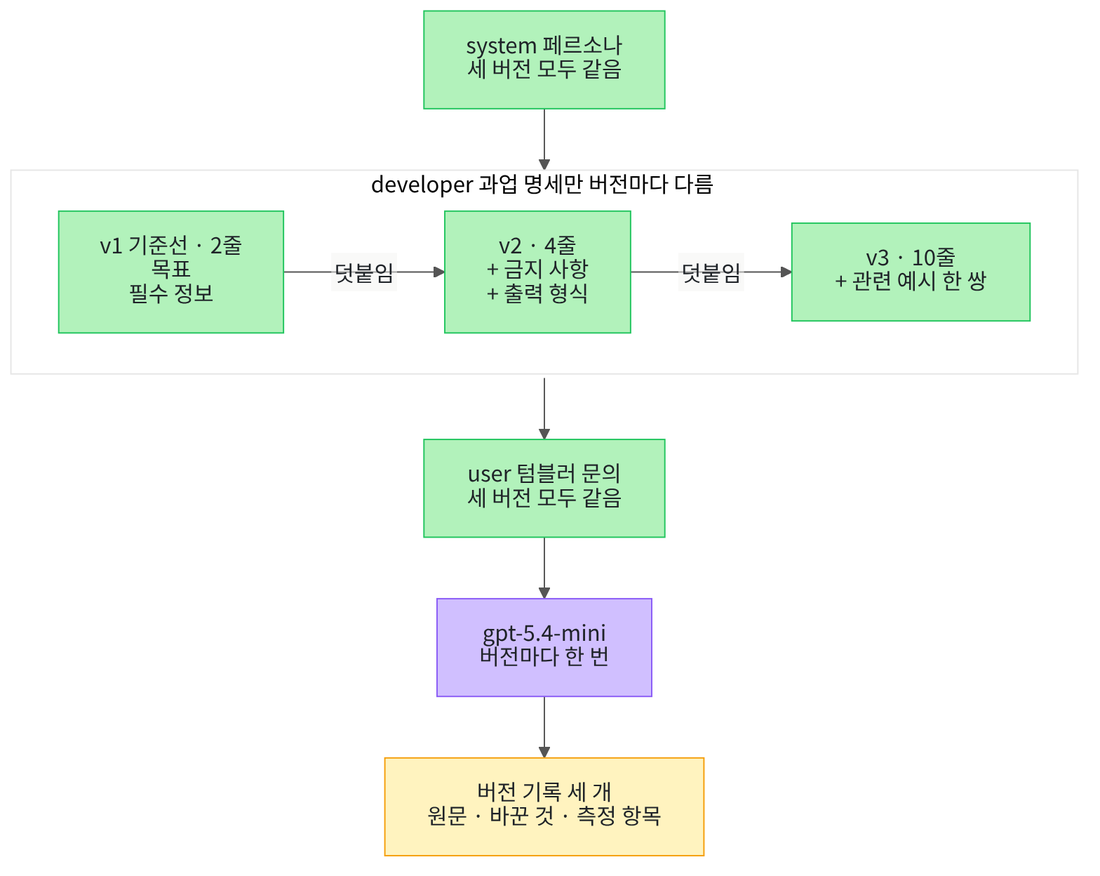

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~07절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

네 가지를 불러옵니다. 시간을 다루는 모듈 `time`은 Ch 6 05절, JSON 글을 다루는 모듈 `json`은 07절에서 썼습니다.
모듈 `hashlib`은 파일 지문을 계산하는 모듈이고, 뜻은 3절에서 풉니다. 넷째 줄은 모델 객체를 만드는 함수를 불러옵니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 6 06절 `timed_invoke()`와 01절 `make_prompt_record()`를 가져옵니다.

In [2]:
# 시간을 다루는 모듈, JSON 글을 다루는 모듈, 파일 지문을 계산하는 모듈, 모델 객체를 만드는 함수를 불러옵니다
import hashlib
import json
import time

from langchain.chat_models import init_chat_model
# Ch 6 06절·01절 기록 함수 두 개를 도구 파일에서 가져옵니다
from llm_tools import make_prompt_record, timed_invoke

01~07절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01~07절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. Ch 6 기록 파일 읽기

Ch 6 06절은 두 모델의 측정 기록과 요금표를 JSON 파일 하나에 저장했습니다. 이 절은 그 파일을 읽어 앞 실행의 이름과 요금을 확인합니다.
파일 경로는 Ch 6 06절처럼 고릅니다. 노트북을 `notebooks` 폴더에서 열면 한 칸 위에 이 실습 폴더의 `runs` 폴더가 있습니다.

그러면 Ch 6 실습 폴더는 두 칸 위 폴더 안의 `ch06-langchain-start`입니다. `../runs` 폴더가 없으면 프로젝트 맨 위 폴더에서 연 경우로 보고 긴 경로를 씁니다.
작업 폴더가 실습 폴더 맨 위이면 두 경로를 모두 찾지 못해 다음 셀에서 멈추므로, `notebooks` 폴더에서 엽니다.
이름 `ch06_relative`에는 프로젝트 맨 위 폴더에서 본 경로를 따로 담습니다. 8절에서 기록 파일에 출처로 적을 경로입니다.

실행 전에 예상합니다. Ch 6 06절 노트북을 실행한 적이 있으면 `True`가 나올 것입니다.

In [5]:
# Ch 6 06절 기록 파일의 경로를 고르고, 파일이 있는지 확인합니다
ch06_relative = "labs/part2/ch06-langchain-start/runs/provider-comparison-continuity.json"
ch06_path = "../../ch06-langchain-start/runs/provider-comparison-continuity.json"
if not os.path.exists("../runs"):
    ch06_path = ch06_relative
has_ch06_file = os.path.exists(ch06_path)
print("Ch 6 기록 파일이 있는가:", has_ch06_file)
assert has_ch06_file, "Ch 6 06절 노트북을 먼저 실행해 기록 파일을 만들어 주세요."

Ch 6 기록 파일이 있는가: True


**결과 읽기** — 출력은 `Ch 6 기록 파일이 있는가: True` 한 줄입니다. `assert`도 통과했습니다.
경로는 컴퓨터마다 달라서 출력하지 않았습니다.

파일을 읽어 JSON 글을 딕셔너리로 바꿉니다. Ch 6 06절 마지막 셀과 같은 `with open` + `json.loads(file.read())` 모양입니다.
최상위 키 목록과 실행 이름, 요금 확인 날짜, mini 요금을 출력합니다.
마지막 줄은 mini 요금이 Ch 6 06절 4절에서 적은 값과 같은지 확인합니다.

실행 전에 예상합니다. 최상위 키는 Ch 6 06절 10절에서 모은 여섯 개일 것입니다.

In [6]:
# 기록 파일을 읽어 최상위 키·실행 이름·요금 확인 날짜·mini 요금을 출력합니다
with open(ch06_path, encoding="utf-8") as file:
    ch06_record = json.loads(file.read())
mini_prices = ch06_record["pricing"]["openai"]
ch06_keys = list(ch06_record.keys())
print("최상위 키:", ch06_keys)
print("Ch 6 실행 이름:", ch06_record["run_id"])
print("요금 확인 날짜:", ch06_record["pricing"]["date"])
print("mini 요금:", mini_prices)
assert mini_prices == {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}

최상위 키: ['run_id', 'run_date', 'source_chapter', 'conditions', 'pricing', 'records']
Ch 6 실행 이름: ch06-provider-20260917T020433
요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 첫 줄은 `최상위 키: ['run_id', 'run_date', 'source_chapter', 'conditions', 'pricing', 'records']`입니다.
둘째 줄은 `Ch 6 실행 이름: ch06-provider-20260917T020433`, 셋째 줄은 `요금 확인 날짜: 2026-09-17`입니다.
넷째 줄은 `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`이고, `assert`도 통과했습니다.

실행 이름 끝의 숫자는 Ch 6 06절을 실행한 시각입니다. 여러분이 그 노트북을 다시 실행했다면 다른 시각이 보입니다.
키 `records`의 기록 줄은 이 절에서 읽지 않습니다. Ch 6 질문은 이 절의 고객 문의와 달라, 토큰 수를 서로 비교하지 않기 때문입니다.

## 3. 파일 지문 만들기

파일 지문(hash)은 파일 안의 바이트 전체로 계산한, 길이가 정해진 글입니다. 내용이 한 글자만 달라져도 전혀 다른 글이 됩니다.
사람 지문을 대 보면 같은 사람인지 알 수 있듯, 두 지문을 비교하면 두 파일의 내용이 같은지 알 수 있습니다.
이 절은 계산 방법 SHA-256을 쓰는 함수 `hashlib.sha256(바이트)`로 계산합니다. 메서드 `hexdigest()`는 결과를 64글자 16진수 글로 반환합니다.

바이트는 글자로 바꾸기 전에 파일에 저장된 값 그대로입니다. 모드 `"rb"`로 열면 글로 바꾸지 않고 바이트를 읽습니다.
모드 글의 r은 읽기, b는 바이트라는 뜻입니다. Part 1에서 쓴 모드 `"w"`·`"a"`처럼 `open()`의 둘째 인자로 적습니다.

실행 전에 예상합니다. 지문 글자 수는 64일 것입니다.

In [7]:
# Ch 6 기록 파일을 바이트 그대로 읽어 SHA-256 지문을 계산합니다
with open(ch06_path, "rb") as file:
    ch06_bytes = file.read()
ch06_sha256 = hashlib.sha256(ch06_bytes).hexdigest()
print("Ch 6 파일 지문:", ch06_sha256)
print("지문 글자 수:", len(ch06_sha256))

Ch 6 파일 지문: f18920c63088bded645bc4712b8ee16436e46d394499bfeaa4cc081f76ef4f4c
지문 글자 수: 64


**결과 읽기** — 둘째 줄은 `지문 글자 수: 64`입니다. 첫 줄의 지문은 숫자 0~9와 영문자 a~f로만 된 64글자 글입니다.
이 지문은 Ch 6 06절 노트북을 다시 실행해 파일이 바뀌면 다른 글이 됩니다. 그래서 설명에서는 지문 글자를 옮겨 적지 않습니다.

내용이 조금 다르면 지문이 얼마나 달라지는지 짧은 글 두 개로 봅니다. 주문번호의 마지막 숫자만 다른 글입니다.
글 메서드 `encode("utf-8")`는 글을 UTF-8 바이트로 바꿔 반환합니다. 파일은 바꾸지 않고, 요청도 보내지 않습니다.

실행 전에 예상합니다. 두 지문은 같지 않을 것입니다.

In [8]:
# 마지막 숫자만 다른 글 두 개의 지문을 비교합니다(요청 없음)
first_bytes = "주문번호 A-1042".encode("utf-8")
second_bytes = "주문번호 A-1043".encode("utf-8")
first_sha256 = hashlib.sha256(first_bytes).hexdigest()
second_sha256 = hashlib.sha256(second_bytes).hexdigest()
print("A-1042 지문:", first_sha256)
print("A-1043 지문:", second_sha256)
print("두 지문이 같은가:", first_sha256 == second_sha256)

A-1042 지문: 0ff2abab6648151388144e8b4578a0f0a39e9b044b17f89fa9d034bbe5be4dec
A-1043 지문: 6099ca9bd296c1a9ecd904486b7ea47d403ca84fc7240b8bb0ca077aab78c8a0
두 지문이 같은가: False


**결과 읽기** — 마지막 줄은 `두 지문이 같은가: False`입니다.
첫 줄은 `A-1042 지문: 0ff2abab`로, 둘째 줄은 `A-1043 지문: 6099ca9b`로 시작해 첫 글자부터 다릅니다.

글자 하나만 달라도 지문 전체가 달라졌습니다. 반대로 내용이 같으면 지문도 같습니다. 9절에서 이 성질로 기록 파일과 사본을 비교합니다.
지문이 같다는 것은 내용이 같다는 뜻일 뿐, 그 내용이 맞다는 뜻은 아닙니다.

## 4. 과업 명세 세 버전 적기

프롬프트 버전(prompt version)은 어느 때의 프롬프트 원문에 이름을 붙인 것입니다. 문서를 고칠 때마다 날짜를 붙여 따로 저장해 두는 것과 비슷합니다.
이 절에서는 과업 명세 원문 하나가 버전 하나이고, 이름은 `v1`·`v2`·`v3`입니다.

01~07절 목록은 system 페르소나, developer 과업 명세, user 고객 문의 세 메시지였습니다.
세 버전은 과업 명세만 다르고, 나머지 두 메시지는 같습니다. 먼저 02절과 같은 글 여섯 개를 다시 만듭니다.

In [9]:
# 02절과 같은 페르소나·고객 문의·과업 명세 네 글을 다시 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
print("페르소나:", persona_text)
print("출력 형식:", format_text)

페르소나: 당신은 친절한 고객 상담원입니다.
출력 형식: 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 두 줄은 `페르소나: 당신은 친절한 고객 상담원입니다.`와 `출력 형식: 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.`입니다.
02~07절에서 쓴 글과 같습니다.

이어서 03절 관련 예시를 다시 만듭니다. 셔츠 단추 문의(B-203)와 세 줄 답을 짝지은 글입니다.
03절은 함수 `make_example_text()`로 만들었습니다. 이 절은 예시를 한 번만 만들므로 같은 모양을 `+`로 바로 잇습니다.

In [10]:
# 03절과 같은 관련 예시 글을 만듭니다(03절 make_example_text()와 같은 모양)
relevant_inquiry = "셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다."
relevant_answer = "분류: 교환 요청(하자)\n"
relevant_answer = relevant_answer + "다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다.\n"
relevant_answer = relevant_answer + "고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다."
relevant_example = "예시 문의: " + relevant_inquiry + "\n" + "예시 답:" + "\n" + relevant_answer
print("관련 예시:")
print(relevant_example)

관련 예시:
예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.
예시 답:
분류: 교환 요청(하자)
다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 다섯 줄이 관련 예시입니다. 첫 줄은 `예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.`입니다.
둘째 줄 `예시 답:` 아래 세 줄이 예시 답입니다.

세 버전을 만듭니다. 버전 `v1`은 목표와 필수 정보 두 글만 이은 기준선(baseline)입니다. 기준선은 뒤 버전과 비교할 출발점입니다.

버전 `v2`는 `v1` 글 뒤에 금지 사항과 출력 형식을 잇습니다. 02절 과업 명세와 같은 글입니다.
버전 `v3`는 `v2` 글 뒤에 빈 줄 하나와 관련 예시를 잇습니다. 03절 관련 예시 목록의 developer 글과 같습니다.

In [11]:
# 뒤 버전이 앞 버전 글에 덧붙이는 모양으로 과업 명세 세 버전을 만듭니다
v1_task = goal_text + "\n" + required_text
v2_task = v1_task + "\n" + forbidden_text + "\n" + format_text
v3_task = v2_task + "\n\n" + relevant_example
print("v1 과업 명세:")
print(v1_task)

v1 과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.


**결과 읽기** — 라벨 줄 아래 두 줄이 기준선 과업 명세입니다. 첫 줄 `고객 문의를 분류하고 필요한 다음 행동을 안내하세요.`는 목표입니다.
둘째 줄은 필수 정보이고, 출력 형식과 금지 사항은 없습니다.

버전 기록은 버전마다 이름·바꾼 것·바꾼 이유·과업 명세 원문을 함께 적은 딕셔너리입니다.
이름만 남기면 나중에 어떤 문장을 보냈는지, 왜 바꿨는지 알 수 없기 때문입니다. 세 기록은 목록 `prompt_versions`에 모읍니다.

출력은 버전마다 이름·바꾼 것·과업 명세 줄 수입니다. 줄 수는 02절처럼 `split("\n")`으로 셉니다.

In [12]:
# 버전마다 이름·바꾼 것·바꾼 이유·과업 명세 원문을 딕셔너리에 적어 목록에 모읍니다
v1_version = {"버전": "v1", "바꾼 것": "기준선", "바꾼 이유": "목표와 필수 정보만 적은 출발점", "과업 명세": v1_task}
v2_version = {"버전": "v2", "바꾼 것": "금지 사항과 출력 형식을 더함", "바꾼 이유": "답 모양을 세 줄로 정하고 보상 약속을 막으려고", "과업 명세": v2_task}
v3_version = {"버전": "v3", "바꾼 것": "관련 예시 한 쌍을 더함", "바꾼 이유": "03절에서 관련 예시 답이 예시 문장 모양을 따름", "과업 명세": v3_task}
prompt_versions = [v1_version, v2_version, v3_version]
print("버전 | 바꾼 것 | 과업 명세 줄 수")
for version in prompt_versions:
    task_lines = version["과업 명세"].split("\n")
    print(version["버전"], "|", version["바꾼 것"], "|", len(task_lines))

버전 | 바꾼 것 | 과업 명세 줄 수
v1 | 기준선 | 2
v2 | 금지 사항과 출력 형식을 더함 | 4
v3 | 관련 예시 한 쌍을 더함 | 10


**결과 읽기** — 라벨 줄 아래 세 줄은 `v1 | 기준선 | 2`, `v2 | 금지 사항과 출력 형식을 더함 | 4`, `v3 | 관련 예시 한 쌍을 더함 | 10`입니다.
버전 `v3`의 10줄은 과업 명세 네 줄, 빈 줄 하나, 예시 다섯 줄입니다.

버전 `v1`에서 `v2`로 갈 때는 글 두 개를 함께 더했습니다. 그래서 두 버전의 차이가 금지 사항 때문인지 출력 형식 때문인지는 나눌 수 없습니다.
바꾼 것에 두 가지를 그대로 적은 이유입니다. 버전 `v2`에서 `v3`로 갈 때는 관련 예시 하나만 더했습니다.

## 5. 비용 함수와 기록 함수

요청마다 Ch 6 06절과 같은 항목을 기록하려고 함수 두 개를 새로 만듭니다. 첫 함수는 예상 비용을 계산합니다.
계산은 Ch 6 06절 `estimate_cost()`와 같습니다. 이 절은 mini 모델만 부르므로 세 요금 인자에 mini 요금을 기본값으로 둡니다.

기본값을 둔 매개변수는 Ch 2 04절에서 배웠습니다. 부를 때 요금을 적지 않으면 기본값으로, 적으면 적은 값으로 계산합니다.
함수 이름에 openai를 붙인 것은 OpenAI mini 요금을 기본값으로 둔 함수라서입니다. 이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [13]:
# 사용량과 세 요금(기본값 mini 요금)으로 요청 한 번의 예상 비용(달러)을 계산하는 함수를 정의합니다
def estimate_openai_cost(usage, input_rate=0.75, cached_input_rate=0.075, output_rate=4.50):
    if usage is None:
        return None
    # 캐시 입력 키가 없으면 할인 없이 모두 입력 요금으로 계산합니다
    details = usage.get("input_token_details", {})
    cache_read = details.get("cache_read", 0)
    normal_input = usage["input_tokens"] - cache_read
    input_cost = normal_input * input_rate + cache_read * cached_input_rate
    output_cost = usage["output_tokens"] * output_rate
    price_unit = 1000000
    return (input_cost + output_cost) / price_unit

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

Ch 6 06절 교재 예로 함수를 확인합니다. 입력 100토큰 가운데 캐시 입력이 40, 출력이 10토큰이면 mini 요금으로 0.000093달러였습니다.
한 번은 기본값으로, 한 번은 2절에서 파일로 읽은 `mini_prices` 요금을 적어 계산합니다.
두 값이 같으면 기본값이 Ch 6 기록 파일의 mini 요금과 같다는 뜻입니다.

실행 전에 예상합니다. 두 줄 모두 0.000093달러일 것입니다.

In [14]:
# Ch 6 06절 교재 예 사용량으로, 기본값과 파일 요금의 계산 결과가 같은지 확인합니다(요청 없음)
example_usage = {"input_tokens": 100, "output_tokens": 10, "input_token_details": {"cache_read": 40}}
default_cost = estimate_openai_cost(example_usage)
file_cost = estimate_openai_cost(
    example_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
print("기본값으로 계산한 비용(달러):", default_cost)
print("파일 요금으로 계산한 비용(달러):", file_cost)
assert default_cost == file_cost and round(default_cost, 6) == 0.000093

기본값으로 계산한 비용(달러): 9.3e-05
파일 요금으로 계산한 비용(달러): 9.3e-05


**결과 읽기** — 두 줄은 `기본값으로 계산한 비용(달러): 9.3e-05`와 `파일 요금으로 계산한 비용(달러): 9.3e-05`입니다. `assert`도 통과했습니다.
출력의 `9.3e-05`는 Ch 6 06절에서 본 대로 0.000093을 짧게 적은 모양입니다.

요청과 기록 한 줄은 준비 셀에서 가져온 `timed_invoke()`와 `make_prompt_record()`로 만듭니다.
기록 키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다. 이 절에서는 조건 이름 자리에 버전 이름을 넣습니다.

Ch 6 06절 기록 줄에는 01절 기록에 없는 키가 세 개 더 있었습니다. `응답한 모델`, `캐시 입력 토큰 수`, `예상 비용(달러)`입니다.
둘째 함수 `add_cost_items()`는 01절 모양 기록에 이 세 키를 더해 반환합니다. 그러면 기록 줄이 Ch 6 06절과 같은 측정 항목을 갖습니다.

캐시 입력 토큰 수는 `estimate_openai_cost()`처럼 `get(키, 기본값)`으로 꺼냅니다. 키가 없는 응답이면 0을 씁니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [15]:
# 01절 모양 기록에 응답한 모델·캐시 입력 토큰 수·예상 비용을 더해 반환하는 함수를 정의합니다
def add_cost_items(record, run_response):
    run_usage = run_response.usage_metadata
    details = run_usage.get("input_token_details", {})
    record["응답한 모델"] = run_response.response_metadata["model_name"]
    record["캐시 입력 토큰 수"] = details.get("cache_read", 0)
    record["예상 비용(달러)"] = estimate_openai_cost(run_usage)
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 6. 세 버전을 한 번씩 보내기

모델·system 페르소나·user 고객 문의는 그대로 두고, developer 자리에 버전의 과업 명세를 넣어 보냅니다.
비교하는 동안 그대로 두는 값을 고정 조건이라고 부릅니다. 버전마다 달라지는 것은 과업 명세 하나입니다.

같은 대상을 두 조건으로 보내 결과를 견주는 방법을 A/B 비교(A/B comparison)라고 부릅니다.
가게 안내문 두 가지를 번갈아 붙이고 손님 반응을 비교하는 것과 비슷합니다. 이 절은 버전이 셋이라, 이웃한 두 버전씩 짝지어 비교합니다.

반복문 안에서는 요청을 보내고 기록을 만들기만 합니다. 만든 기록은 버전 딕셔너리의 새 키 `기록`에 담습니다.
답은 요청이 모두 끝난 뒤 다음 셀에서 출력합니다.

실행 전에 예상합니다. 출력 형식이 없는 기준선 답은 세 줄 모양이 아닐 수 있습니다.

In [16]:
# 세 버전의 과업 명세로 목록을 만들어 한 번씩 보내고, 기록을 버전 딕셔너리에 담습니다(요청 3번)
for version in prompt_versions:
    version_messages = [("system", persona_text), ("developer", version["과업 명세"]), ("user", inquiry_text)]
    run_response, run_elapsed = timed_invoke(model, version_messages)
    record = make_prompt_record(version["버전"], run_response, run_elapsed)
    version["기록"] = add_cost_items(record, run_response)
v3_record_keys = list(prompt_versions[2]["기록"].keys())
print("v3 기록의 키:", v3_record_keys)

v3 기록의 키: ['조건', '답', '입력 토큰 수', '출력 토큰 수', '끝난 이유', '걸린 초', '응답한 모델', '캐시 입력 토큰 수', '예상 비용(달러)']


**결과 읽기** — 출력은 `v3 기록의 키: ['조건', '답', '입력 토큰 수', '출력 토큰 수', '끝난 이유', '걸린 초', '응답한 모델', '캐시 입력 토큰 수', '예상 비용(달러)']` 한 줄입니다.
01절 키 여섯 개 뒤에 Ch 6 06절 키 세 개가 붙었습니다. 요청 3번이 모두 끝난 뒤에 출력했습니다.

세 버전의 답을 차례로 출력합니다. 버전마다 이름 줄을 먼저 출력하고, 그 아래에 답 글을 그대로 출력합니다.

In [17]:
# 세 버전의 답 글을 그대로 출력합니다
for version in prompt_versions:
    print(version["버전"], "답:")
    print(version["기록"]["답"])

v1 답:
안녕하세요. 문의 주셔서 감사합니다.

말씀해 주신 내용은 **교환 접수**로 안내드릴 수 있습니다.  
다만 **회사 규정상 교환 접수 시 파손 사진이 필요**합니다.

- **주문번호:** A-1042
- **요청 내용:** 텀블러 뚜껑 파손으로 새 상품 교환 희망

다음으로 **파손된 뚜껑 사진**을 보내주시면 교환 접수를 도와드리겠습니다.  
사진 확인 후 빠르게 안내드리겠습니다.
v2 답:
분류: 교환 요청(파손)
다음 행동: 교환 접수를 위해 파손된 뚜껑 사진을 보내주세요. 주문번호 A-1042 확인했습니다.
고객에게 보낼 한 문장: 주문번호 A-1042의 텀블러 뚜껑 파손으로 교환을 원하시면, 파손 사진을 보내주시면 접수 도와드리겠습니다.
v3 답:
분류: 교환 요청(파손)
다음 행동: 파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 뚜껑이 깨진 부분의 사진을 보내 주시면 주문번호 A-1042로 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 `v1 답:` 아래 답은 `안녕하세요. 문의 주셔서 감사합니다.`로 시작합니다.
굵은 글씨 표시(`**`)와 `- **주문번호:** A-1042` 같은 줄 목록이 섞인 긴 답입니다.
라벨 줄 `v2 답:`과 `v3 답:` 아래 답은 모두 `분류: 교환 요청(파손)`으로 시작하는 세 줄입니다.
세 답 모두 주문번호 A-1042와 파손 사진을 적었고, 보상 약속은 없었습니다.

기준선 과업 명세에는 금지 사항이 없었지만, 이번 기준선 답도 보상을 약속하지 않았습니다. 이것만으로 금지 사항이 필요 없다고 말하지는 않습니다.
버전 `v3` 답의 다음 행동 줄 `파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다.`는 예시 답 문장 모양을 따랐습니다. 03절에서 본 모양과 비슷합니다.

교재를 만들 때 탐색 실행과 앞선 새 커널 실행에서도 기준선 답은 여러 줄 목록, 나머지 두 답은 세 줄이었습니다.

## 7. 같은 항목으로 비교하기

세 기록을 Ch 6 06절 기록표와 같은 항목으로 출력합니다. 첫 열은 01~07절처럼 키 `조건`의 값이고, 이 절에서는 버전 이름입니다.
마지막 줄은 응답 메타데이터에 적힌 응답한 모델 이름입니다.

실행 전에 예상합니다. 입력 토큰 수는 글을 덧붙인 순서로 늘 것입니다.
버전 `v2`와 `v3`는 02·03절과 같은 목록이라, 입력 토큰 수도 02·03절의 134·225와 같을 것입니다.

In [18]:
# 세 기록을 Ch 6 06절과 같은 측정 항목으로 한 줄씩 출력합니다
print("기록표(버전 | 입력 | 캐시 입력 | 출력 | 끝난 이유 | 걸린 초 | 예상 비용):")
for version in prompt_versions:
    record = version["기록"]
    print(
        record["조건"], "|", record["입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|", record["출력 토큰 수"], "|",
        record["끝난 이유"], "|", record["걸린 초"], "|", record["예상 비용(달러)"],
    )
print("응답한 모델:", prompt_versions[0]["기록"]["응답한 모델"])

기록표(버전 | 입력 | 캐시 입력 | 출력 | 끝난 이유 | 걸린 초 | 예상 비용):
v1 | 100 | 0 | 128 | stop | 1.14 | 0.000651
v2 | 134 | 0 | 94 | stop | 1.14 | 0.0005235
v3 | 225 | 0 | 77 | stop | 0.82 | 0.00051525
응답한 모델: gpt-5.4-mini-2026-03-17


**결과 읽기** — 라벨 줄 아래 세 줄은 `v1 | 100 | 0 | 128 | stop | 1.14 | 0.000651`, `v2 | 134 | 0 | 94 | stop | 1.14 | 0.0005235`, `v3 | 225 | 0 | 77 | stop | 0.82 | 0.00051525`입니다.
마지막 줄은 `응답한 모델: gpt-5.4-mini-2026-03-17`입니다.

예상대로 입력 토큰 수는 100·134·225로 늘었고, 134와 225는 02·03절과 같았습니다. 캐시 입력은 세 줄 모두 0이었습니다.
출력 토큰 수는 입력 순서와 반대로 128·94·77이었습니다. 긴 목록으로 답한 기준선의 출력이 가장 많았습니다.

예상 비용은 기준선이 가장 컸습니다. 출력 요금이 입력 요금의 6배라, 출력 토큰 수의 차이가 비용을 더 크게 바꿨습니다.

앞선 새 커널 실행에서는 출력이 143·101·85였고, 예상 비용 순서는 이번과 같았습니다. 버전 `v3`는 입력이 91토큰 많아, 출력이 약 15토큰 넘게 적을 때만 더 쌉니다.
이번 출력 차이는 17이라 그 기준에 가깝고, 다음 실행에서는 비용 순서가 바뀔 수 있습니다.
걸린 초도 한 번 잰 값이라 속도 비교에 쓰지 않습니다.

답 모양은 02절처럼 줄 수와 첫 줄로 봅니다. 01절 확인 단어 세 개가 답에 있는지도 표시합니다.
이 표시는 품질 점수가 아니라, 원문을 읽을 곳을 찾는 도구입니다.

In [19]:
# 버전마다 답의 줄 수·첫 줄과, 확인 단어 세 개가 답에 있는지 출력합니다
check_words = ["교환", "A-1042", "사진"]
print("버전 | 줄 수 | 첫 줄 | 확인 단어 표시")
for version in prompt_versions:
    answer_lines = version["기록"]["답"].split("\n")
    word_flags = []
    for word in check_words:
        word_flags.append(word in version["기록"]["답"])
    print(version["버전"], "|", len(answer_lines), "|", answer_lines[0], "|", word_flags)

버전 | 줄 수 | 첫 줄 | 확인 단어 표시
v1 | 10 | 안녕하세요. 문의 주셔서 감사합니다. | [True, True, True]
v2 | 3 | 분류: 교환 요청(파손) | [True, True, True]
v3 | 3 | 분류: 교환 요청(파손) | [True, True, True]


**결과 읽기** — 라벨 줄 아래 첫 줄은 `v1 | 10 | 안녕하세요. 문의 주셔서 감사합니다. | [True, True, True]`입니다.
둘째·셋째 줄은 `v2 | 3 | 분류: 교환 요청(파손) | [True, True, True]`와 `v3 | 3 | 분류: 교환 요청(파손) | [True, True, True]`입니다.

출력 형식을 더한 두 버전만 세 줄로 답했고, 첫 줄도 분류 줄이었습니다. 기준선 답은 빈 줄을 포함해 10줄이었습니다.
확인 단어 표시는 세 버전 모두 같아, 답 모양의 차이를 보여 주지 못합니다. 01절에서 정한 대로 이 표시는 품질 점수가 아닙니다.
세 답이 업무에 맞는지는 6절 원문을 읽고 판단했습니다.

## 8. 기록 파일로 남기기

기록은 노트북을 닫으면 사라집니다. 그래서 세 버전 기록을 JSON 파일 하나에 저장합니다.
실행 조건과 결과를 나중에 다시 읽을 수 있게 남긴 파일을 이 절에서는 실행 기록 파일이라고 부릅니다.

최상위 키 여섯 개는 영어로 둡니다. Ch 8 06절 노트북이 이 이름으로 이 파일을 읽기 때문입니다. 버전 기록의 키는 한국어 그대로입니다.

키 `source_record`에는 출처를 적습니다. 2절 경로 `ch06_relative`, 3절 지문, Ch 6 실행 이름입니다.
키 `settings`에는 고정 조건과 요금을, 키 `versions`에는 버전 기록 목록을 담습니다.

실행 이름은 Ch 6 06절처럼 `ch07-prompt-ab-`에 지금 시각을 이어 만듭니다.
실행 전에 예상합니다. 최상위 키는 여섯 개이고, 출처의 실행 이름은 2절 Ch 6 실행 이름과 같을 것입니다.

In [20]:
# 실행 이름·출처·고정 조건·버전 기록을 딕셔너리 하나에 모읍니다
run_stamp = time.strftime("%Y%m%dT%H%M%S")
source_record = {"path": ch06_relative, "sha256": ch06_sha256, "run_id": ch06_record["run_id"]}
settings = {"model": "openai:gpt-5.4-mini", "temperature": 0, "reasoning_effort": "none", "repetitions": 1,
            "system": persona_text, "user": inquiry_text, "check_words": check_words,
            "pricing_date": ch06_record["pricing"]["date"], "pricing_usd_per_million": mini_prices}
run_record = {"run_id": "ch07-prompt-ab-" + run_stamp, "run_date": time.strftime("%Y-%m-%d"),
              "source_chapter": "ch07", "source_record": source_record, "settings": settings, "versions": prompt_versions}
run_keys = list(run_record.keys())
print("실행 이름:", run_record["run_id"])
print("최상위 키:", run_keys)
print("출처의 Ch 6 실행 이름:", run_record["source_record"]["run_id"])

실행 이름: ch07-prompt-ab-20260921T034935
최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'versions']
출처의 Ch 6 실행 이름: ch06-provider-20260917T020433


**결과 읽기** — 첫 줄은 `실행 이름: ch07-prompt-ab-`로 시작하고, 뒤에 이 셀을 실행한 시각이 붙습니다.
둘째 줄은 `최상위 키: ['run_id', 'run_date', 'source_chapter', 'source_record', 'settings', 'versions']`입니다.
셋째 줄은 `출처의 Ch 6 실행 이름: ch06-provider-20260917T020433`으로, 2절에서 읽은 이름과 같습니다.

파일은 이 실습 폴더의 `runs` 폴더에 씁니다. 경로는 2절처럼 `../runs` 폴더가 있는지로 고릅니다.
같은 내용의 사본은 `runs/continuity` 아래에 실행 시각 이름의 폴더를 새로 만들어 씁니다. 기록 파일은 실행할 때마다 덮어쓰지만, 사본은 실행마다 남습니다.

함수 `os.makedirs(경로)`는 경로의 폴더를 만듭니다. 중간 폴더가 없으면 함께 만들고, 이미 있는 폴더면 오류를 냅니다.
그래서 앞선 실행의 사본을 덮어쓰지 않습니다. 파일 쓰기는 Ch 6 06절과 같은 `json.dumps()` + `with open` 모양입니다.

실행 전에 예상합니다. 두 파일이 모두 있다는 `True` 두 줄이 나올 것입니다.

In [21]:
# runs 폴더에 기록 파일을 쓰고, 실행 시각 이름의 폴더를 새로 만들어 같은 내용의 사본도 씁니다
runs_folder = "../runs"
if not os.path.exists("../runs"):
    runs_folder = "labs/part2/ch07-prompt-engineering/runs"
record_path = runs_folder + "/prompt-ab-continuity.json"
copy_folder = runs_folder + "/continuity/" + run_stamp
os.makedirs(copy_folder)
copy_path = copy_folder + "/prompt-ab-continuity.json"
payload = json.dumps(run_record, ensure_ascii=False, indent=2)
with open(record_path, "w", encoding="utf-8") as file:
    file.write(payload)
with open(copy_path, "w", encoding="utf-8") as file:
    file.write(payload)
print("기록 파일이 있는가:", os.path.exists(record_path))
print("사본이 있는가:", os.path.exists(copy_path))

기록 파일이 있는가: True
사본이 있는가: True


**결과 읽기** — 두 줄은 `기록 파일이 있는가: True`와 `사본이 있는가: True`입니다.
파일 경로는 컴퓨터마다 달라서 출력하지 않았습니다.
이 셀만 다시 실행하면 `os.makedirs()`에서 `FileExistsError`가 납니다. 앞 셀에서 만든 실행 시각 폴더가 이미 있기 때문이고, 기록 파일도 바뀌지 않습니다.
8절 첫 셀부터 다시 실행하면 새 실행 이름으로 기록 파일을 덮어쓰고, 사본 폴더가 하나 더 생깁니다.

## 9. 다시 읽어 출처와 사본 확인하기

쓴 파일을 다시 읽어 세 가지를 확인합니다. 실행 이름이 같은지, 출처 지문이 3절 지문과 같은지, 버전이 세 개인지입니다.
기록 파일과 사본도 바이트로 읽어 지문을 비교합니다. 3절에서는 한 글자만 달라도 지문이 달라졌습니다. 그래서 두 지문이 같으면 두 파일의 내용도 같다고 봅니다.

실행 전에 예상합니다. 세 줄은 `True`이고, 버전 수는 3일 것입니다.

In [22]:
# 쓴 기록 파일을 다시 읽어 실행 이름·출처 지문·버전 수를 확인하고, 사본과 지문을 비교합니다
with open(record_path, encoding="utf-8") as file:
    saved = json.loads(file.read())
with open(record_path, "rb") as file:
    record_bytes = file.read()
with open(copy_path, "rb") as file:
    copy_bytes = file.read()
record_sha256 = hashlib.sha256(record_bytes).hexdigest()
copy_sha256 = hashlib.sha256(copy_bytes).hexdigest()
print("다시 읽은 실행 이름이 같은가:", saved["run_id"] == run_record["run_id"])
print("출처 지문이 Ch 6 파일 지문과 같은가:", saved["source_record"]["sha256"] == ch06_sha256)
print("버전 수:", len(saved["versions"]))
print("기록 파일과 사본의 지문이 같은가:", record_sha256 == copy_sha256)
assert saved["source_record"]["sha256"] == ch06_sha256 and record_sha256 == copy_sha256

다시 읽은 실행 이름이 같은가: True
출처 지문이 Ch 6 파일 지문과 같은가: True
버전 수: 3
기록 파일과 사본의 지문이 같은가: True


**결과 읽기** — 네 줄은 `다시 읽은 실행 이름이 같은가: True`, `출처 지문이 Ch 6 파일 지문과 같은가: True`, `버전 수: 3`, `기록 파일과 사본의 지문이 같은가: True`입니다.
`assert`도 통과했습니다.

이제 이 기록 파일은 Ch 6 기록 파일의 경로·지문·실행 이름을 출처로 품습니다. Ch 6 06절 노트북을 다시 실행하면 그 파일의 지문이 바뀝니다.
그러면 이 파일에 적힌 출처 지문과 맞지 않게 되므로, 이 노트북도 다시 실행해 출처를 새로 적습니다.

앞 파일의 지문을 뒤 파일이 적어 두는 이런 연결을 이 절에서는 기록 사슬이라고 부릅니다.
Ch 8 06절 노트북도 같은 세 키로 이 파일의 경로·지문·실행 이름을 적습니다.

## 10. 값 바꿔 보기 — 세 버전을 한 번 더 보내기

바꾸는 값은 버전마다 보내는 횟수 하나입니다. 8절 `settings`의 `repetitions`는 1이었고, 이번에는 세 버전을 한 번씩 더 보내 2로 만듭니다.
목록·모델·고정 조건은 6절과 같습니다. 두 번째 기록은 목록 `second_records`에 따로 모으고, 8절 파일에는 넣지 않습니다.

한 번씩만 보낸 비교로는 버전 사이의 차이와 같은 버전 안의 차이를 나누지 못합니다. 두 번째 실행으로 같은 버전 안에서 무엇이 달라지는지 봅니다.
실행 전에 예상합니다. 입력 토큰 수는 버전마다 같고, 출력 토큰 수와 답 문장은 달라질 수 있습니다.

In [23]:
# 세 버전을 한 번씩 더 보내고, 두 번째 기록을 따로 모읍니다(요청 3번, 파일에는 넣지 않습니다)
second_records = []
for version in prompt_versions:
    version_messages = [("system", persona_text), ("developer", version["과업 명세"]), ("user", inquiry_text)]
    run_response, run_elapsed = timed_invoke(model, version_messages)
    record = make_prompt_record(version["버전"], run_response, run_elapsed)
    second_records.append(add_cost_items(record, run_response))
print("두 번째 기록 수:", len(second_records))

두 번째 기록 수: 3


**결과 읽기** — 출력은 `두 번째 기록 수: 3` 한 줄입니다. 요청 3번이 모두 끝난 뒤에 출력했습니다.

버전마다 첫 실행과 두 번째 실행을 나란히 봅니다. 함수 `range(len(second_records))`는 번호 0·1·2를 차례로 만듭니다.
같은 번호로 `prompt_versions`와 `second_records`에서 같은 버전의 기록을 꺼냅니다. 마지막 열은 두 답이 글자까지 같은지입니다.

In [24]:
# 버전마다 첫 실행과 두 번째 실행의 입력·출력 토큰 수·줄 수와, 답이 글자까지 같은지 출력합니다
print("버전 | 입력(첫·둘째) | 출력(첫·둘째) | 줄 수(첫·둘째) | 답이 같은가")
for index in range(len(second_records)):
    first_record = prompt_versions[index]["기록"]
    second_record = second_records[index]
    first_lines = first_record["답"].split("\n")
    second_lines = second_record["답"].split("\n")
    same_answer = first_record["답"] == second_record["답"]
    print(
        first_record["조건"], "|", first_record["입력 토큰 수"], second_record["입력 토큰 수"], "|",
        first_record["출력 토큰 수"], second_record["출력 토큰 수"], "|", len(first_lines), len(second_lines), "|", same_answer,
    )

버전 | 입력(첫·둘째) | 출력(첫·둘째) | 줄 수(첫·둘째) | 답이 같은가
v1 | 100 100 | 128 141 | 10 14 | False
v2 | 134 134 | 94 83 | 3 3 | False
v3 | 225 225 | 77 77 | 3 3 | True


**결과 읽기** — 라벨 줄 아래 세 줄은 `v1 | 100 100 | 128 141 | 10 14 | False`, `v2 | 134 134 | 94 83 | 3 3 | False`, `v3 | 225 225 | 77 77 | 3 3 | True`입니다.
입력 토큰 수는 세 버전 모두 첫 실행과 같았습니다. 버전 `v3`만 두 답이 글자까지 같았습니다.

버전 `v1`은 출력 토큰 수가 128에서 141로, 줄 수는 10에서 14로 달랐습니다. 목록 모양이 실행마다 달라진 것입니다.
버전 `v2`는 출력 토큰 수가 94에서 83으로 11 줄었습니다. 첫 실행에서 `v2`와 `v3`의 출력 차이는 17이었습니다.
같은 버전 안에서도 11만큼 달라졌으므로, 한 번 잰 차이 17을 모두 예시 때문이라고 볼 수 없습니다.

앞선 새 커널 실행에서는 `v3`의 두 답도 출력 85·77로 달랐습니다. 두 번째 답 글을 출력해, 무엇이 달라졌는지 원문으로 봅니다.

In [25]:
# 두 번째 실행에서 받은 세 버전의 답 글을 그대로 출력합니다
for record in second_records:
    print(record["조건"], "두 번째 답:")
    print(record["답"])

v1 두 번째 답:
안녕하세요. 문의 주셔서 감사합니다.

말씀하신 내용은 **교환 접수**로 안내드릴 수 있습니다.  
다만 **회사 규정상 교환 접수에는 파손 사진이 필요**합니다.

### 확인된 주문 정보
- **주문번호: A-1042**

### 다음 단계
1. **깨진 뚜껑 사진**을 보내주세요.  
   - 파손 부위가 잘 보이게 촬영해 주세요.
2. 사진 확인 후 **새 상품 교환 접수**를 도와드리겠습니다.

사진을 보내주시면 바로 이어서 처리해드릴게요.
v2 두 번째 답:
분류: 파손/교환 요청  
다음 행동: 교환 접수를 위해 깨진 뚜껑의 파손 사진을 보내주시면 확인 후 진행하겠습니다.  
고객에게 보낼 한 문장: 주문번호 A-1042 확인되었으며, 파손 사진을 보내주시면 새 상품 교환 가능 여부를 안내드리겠습니다.
v3 두 번째 답:
분류: 교환 요청(파손)
다음 행동: 파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 뚜껑이 깨진 부분의 사진을 보내 주시면 주문번호 A-1042로 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 `v1 두 번째 답:` 아래 답은 `안녕하세요. 문의 주셔서 감사합니다.`로 시작합니다.
첫 실행 답과 달리 `### 확인된 주문 정보`와 `### 다음 단계` 제목, 번호 목록으로 답했습니다.

라벨 줄 `v2 두 번째 답:` 아래 답은 세 줄 모두 첫 실행과 다릅니다. 첫 줄도 `분류: 파손/교환 요청`으로, 첫 실행의 `분류: 교환 요청(파손)`과 이름이 다릅니다.
라벨 줄 `v3 두 번째 답:` 아래 답은 첫 실행 답과 글자까지 같습니다.

## 실험 결과 해석

세 버전은 과업 명세만 달랐고, 기록 파일에 원문·바꾼 것·바꾼 이유와 같은 측정 항목을 함께 남겼습니다.
출력 형식을 더한 버전 `v2`부터 답이 세 줄 분류 모양이 됐고, 이 차이는 두 번 보낸 결과에서 모두 같았습니다.

반면 `v2`와 `v3`의 첫 실행 출력 차이는 17이었고, 같은 `v2`를 다시 보내도 11만큼 달라졌습니다.
한 번씩 보낸 A/B 비교로는 이런 작은 차이를 버전 탓으로 정할 수 없습니다. 버전마다 같은 횟수로 보내고, 그 횟수를 `repetitions`처럼 기록에 적습니다.

기준선에서 `v2`로 갈 때는 금지 사항과 출력 형식을 함께 더했습니다. 그래서 세 줄 모양이 두 글 가운데 어느 글 때문인지는 나누지 못합니다.
세 버전 모두 보상 약속이 없었으므로, 금지 사항의 효과도 이번 실행에서는 보이지 않았습니다.

이 결론은 고객 문의 하나·모델 하나·버전마다 두 번 보낸 범위입니다. 확인 단어 표시와 토큰 수로는 답의 품질을 판정하지 않았습니다.
걸린 초는 한 번 잰 값이라 속도 비교에 쓰지 않았습니다.

## 정리

- Ch 6 기록 파일의 지문을 계산해, 이 절 기록 파일에 경로·지문·실행 이름을 출처로 적고 사본과 지문을 비교했습니다.
- 과업 명세만 다른 세 버전을 원문·바꾼 것·바꾼 이유와 함께 기록하고, Ch 6 06절과 같은 측정 항목으로 비교했습니다.
- 출력 형식을 더한 버전부터 답이 세 줄이 됐습니다. 같은 `v2`를 다시 보낸 출력 차이(11)도 `v2`·`v3` 차이(17)와 크게 다르지 않았습니다.

다음 09절은 이 챕터의 실습입니다. 04절 틀에 07절 세 층 검사와 이 절의 버전 기록 모양을 붙여, 허용 이름 하나만 바꾼 두 버전을 비교합니다.
09절은 이 절의 기록 파일을 읽거나 고치지 않습니다. 이 파일을 읽는 Ch 8 06절 연결은 09절 끝에서 안내합니다.